# Diabetes Prediction using Machine Learning

## Part 1 - Data Preparation


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: preprocessing, model, evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

In [9]:
data = pd.read_csv("/content/diabetes.csv")
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Explore the dataset

Requirement 2: shape, column names, data types, missing values, and statistical summary.

In [10]:
# a. Shape (rows, columns)
print('Shape (rows, columns):', data.shape)

# b. Column names
print('\nColumns:', list(data.columns))
# c. Data types + non-null counts
data.info()
# d. Missing values reported by pandas (NaN)
print('NaN values per column:')
print(data.isna().sum())
# e. Basic statistical summary
data.describe()
# Target class balance (0 = No Diabetes, 1 = Diabetes)
print(data['Outcome'].value_counts())
print('\nClass proportions:')
print(data['Outcome'].value_counts(normalize=True).round(3))

Shape (rows, columns): (768, 9)

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
NaN values per column:
Pregnancies                 0
Glucose             

In [11]:
# Columns where a value of 0 is biologically impossible, so considering them as missing
cols_with_hidden_na = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print('Count of 0-values (hidden missing) per column:')
print((data[cols_with_hidden_na] == 0).sum())

Count of 0-values (hidden missing) per column:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [12]:
X = data.drop(columns=['Outcome'])  # Features (independent variables)
y = data['Outcome']                 # Target (dependent variable)

print('Features (X) shape:', X.shape)
print('Target (y) shape  :', y.shape)
X.head()

Features (X) shape: (768, 8)
Target (y) shape  : (768,)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


###  Exploratory Data Analysis (EDA)

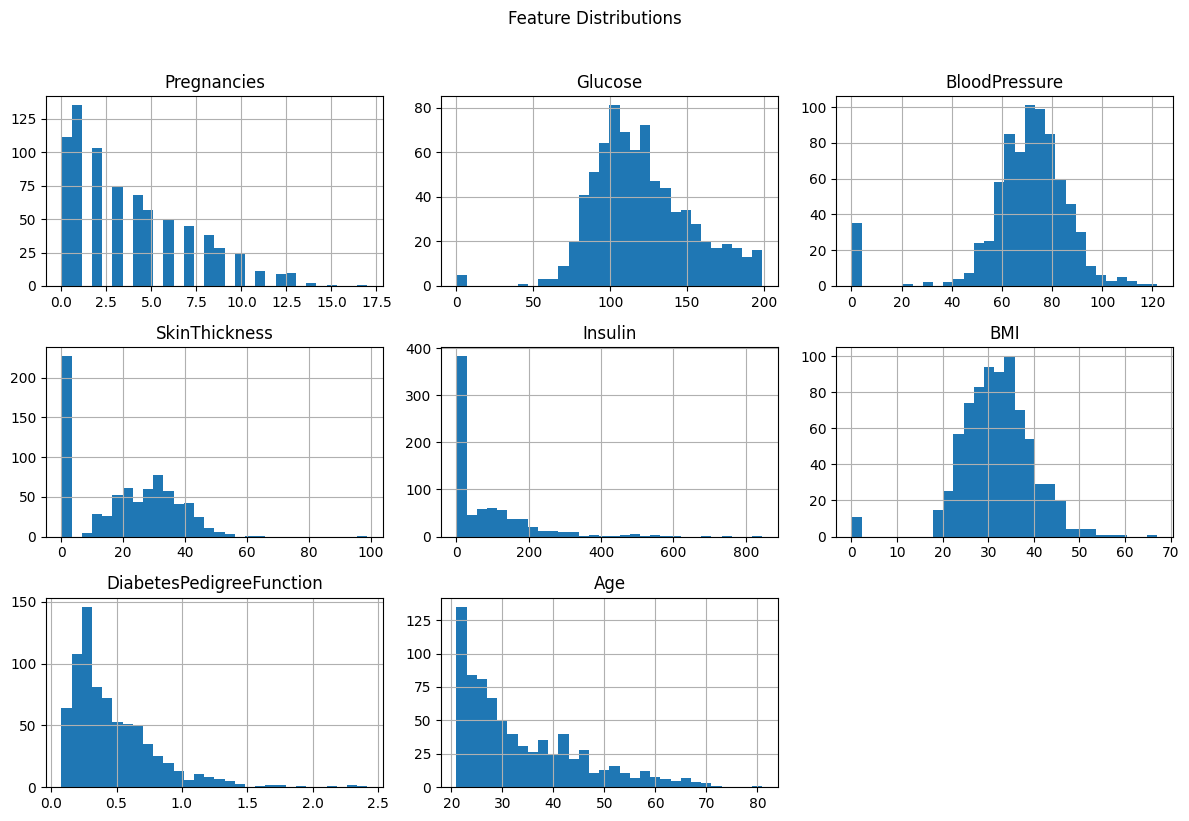

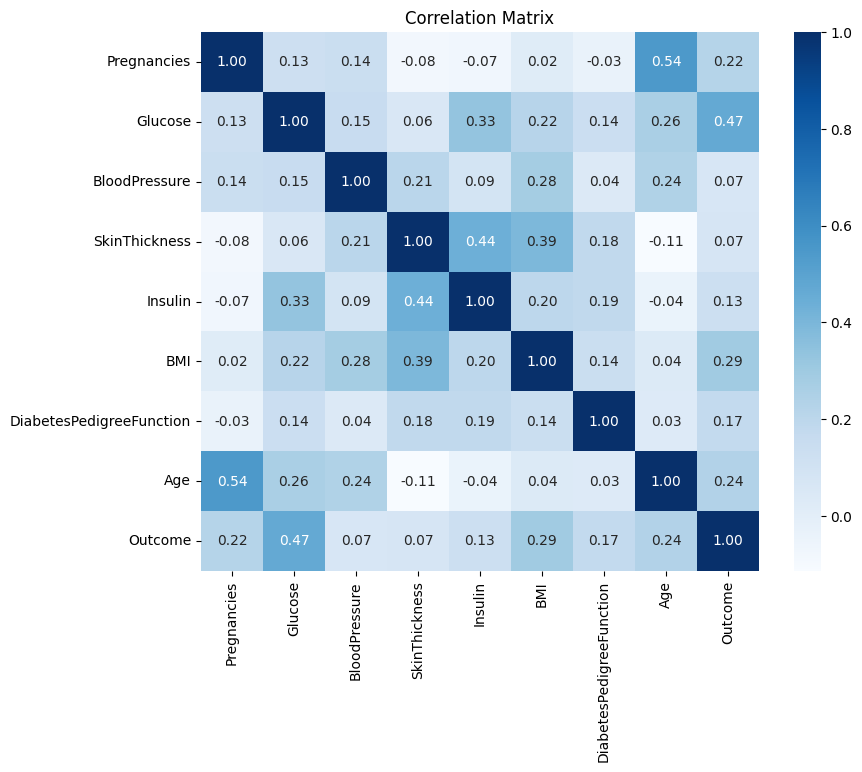

Correlation of each feature with Outcome:
Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


In [13]:
# Distribution of every feature
X.hist(figsize=(12, 8), bins=30)
plt.suptitle('Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()
# Correlation heatmap (which features move with Outcome)
plt.figure(figsize=(9, 7))
sns.heatmap(data.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

print('Correlation of each feature with Outcome:')
print(data.corr()['Outcome'].sort_values(ascending=False))

# Train-Test Split

Requirement 4. An 80/20 split with:
- `random_state` -> reproducible results,
- `stratify=y` -> keeps the same diabetic/non-diabetic ratio in both sets (important because the classes are imbalanced ~65/35).

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print('Training set:', X_train.shape, '| Test set:', X_test.shape)
print('Train class balance:\n', y_train.value_counts(normalize=True).round(3))
print('Test  class balance:\n', y_test.value_counts(normalize=True).round(3))

Training set: (614, 8) | Test set: (154, 8)
Train class balance:
 Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64
Test  class balance:
 Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


###  Preprocessing: impute hidden missing values + scale


In [20]:
# Work on copies so the originals stay intact
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# 1) Replace impossible 0s with NaN in the affected columns
X_train_clean[cols_with_hidden_na] = X_train_clean[cols_with_hidden_na].replace(0, np.nan)
X_test_clean[cols_with_hidden_na] = X_test_clean[cols_with_hidden_na].replace(0, np.nan)

# 2) Impute using the TRAIN median (no leakage from test)
train_medians = X_train_clean.median()
X_train_clean = X_train_clean.fillna(train_medians)
X_test_clean = X_test_clean.fillna(train_medians)

print('Any NaN left in train/test?', X_train_clean.isna().any().any(), X_test_clean.isna().any().any())
# 3) Standardize features (fit on train, transform both)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

print('Scaled training feature means (~0):', np.round(X_train_scaled.mean(axis=0), 2))
print('Scaled training feature stds  (~1):', np.round(X_train_scaled.std(axis=0), 2))

Any NaN left in train/test? False False
Scaled training feature means (~0): [-0. -0.  0. -0. -0.  0. -0. -0.]
Scaled training feature stds  (~1): [1. 1. 1. 1. 1. 1. 1. 1.]


## Part 2 - Machine Learning Model Building

In [ ]:
### Selected algorithm: Logistic Regression

**Why Logistic Regression is a good fit for this problem:**
- The target is **binary** (diabetes vs no diabetes) - exactly the problem Logistic Regression is designed for.
- It models the **probability** of the positive class using the sigmoid function, so we get calibrated-ish probabilities, not just a hard label - useful in a medical screening context.
- It is **interpretable**: each feature gets a coefficient, so we can see which medical attributes push the prediction toward diabetes (clinicians value this).
- It is **fast, simple, and a strong baseline** on small, mostly linearly-separable tabular datasets like this one (768 rows, 8 features).
- It works well with the standardized numeric features we prepared.


In [21]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)
print('Model trained:', model)

Model trained: LogisticRegression(max_iter=1000, random_state=42)


## Part 3 - Model Training & Evaluation

### 3.1 Training performance
Generate predictions on the training set and measure training accuracy.

In [22]:
train_predictions = model.predict(X_train_scaled)
train_accuracy = accuracy_score(y_train, train_predictions)
print(f'Training accuracy: {train_accuracy:.4f}')

Training accuracy: 0.7964


### 3.2 Test performance
Accuracy, precision, recall, F1-score, and the full classification report on unseen test data.

In [23]:
test_predictions = model.predict(X_test_scaled)

test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions)
test_recall = recall_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions)

print(f'Test accuracy : {test_accuracy:.4f}')
print(f'Precision     : {test_precision:.4f}')
print(f'Recall        : {test_recall:.4f}')
print(f'F1-score      : {test_f1:.4f}')
print('\nFull classification report:\n')
print(classification_report(y_test, test_predictions, target_names=['No Diabetes', 'Diabetes']))

Test accuracy : 0.7078
Precision     : 0.6000
Recall        : 0.5000
F1-score      : 0.5455

Full classification report:

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



### 3.3 Confusion Matrix

Confusion matrix:
 [[82 18]
 [27 27]]


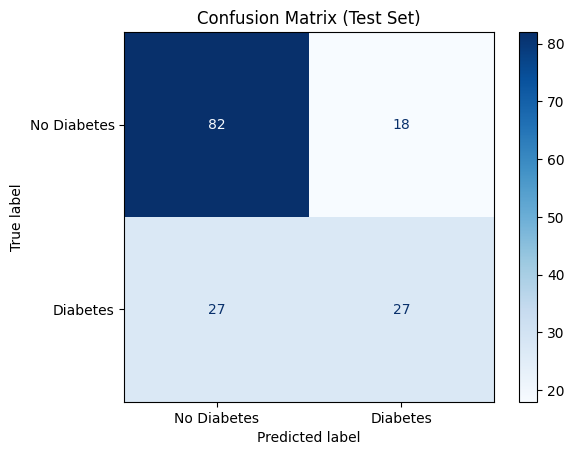

In [24]:
cm = confusion_matrix(y_test, test_predictions)
print('Confusion matrix:\n', cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (Test Set)')
plt.show()

### 3.4 Compare training vs test performance
A large train-vs-test gap would indicate **overfitting**; similar scores indicate the model **generalises** well.

In [25]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy'],
    'Training': [train_accuracy],
    'Test': [test_accuracy],
})
comparison['Gap (Train - Test)'] = comparison['Training'] - comparison['Test']
comparison.round(4)

,Metric,Training,Test,Gap (Train - Test)
0,Accuracy,0.7964,0.7078,0.0886


## Part 4 - Model Performance Analysis

### 4.1 Which features drive the prediction?
Because the inputs are standardized, the magnitude of each Logistic Regression coefficient shows how strongly that feature influences the diabetes prediction (positive = pushes toward diabetes).

                 Feature  Coefficient
                 Glucose     1.182567
                     BMI     0.688652
             Pregnancies     0.377446
DiabetesPedigreeFunction     0.233337
                     Age     0.147794
           SkinThickness     0.028321
           BloodPressure    -0.044111
                 Insulin    -0.066119


/tmp/ipykernel_2463/362767863.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coefficients, x='Coefficient', y='Feature', palette='viridis')


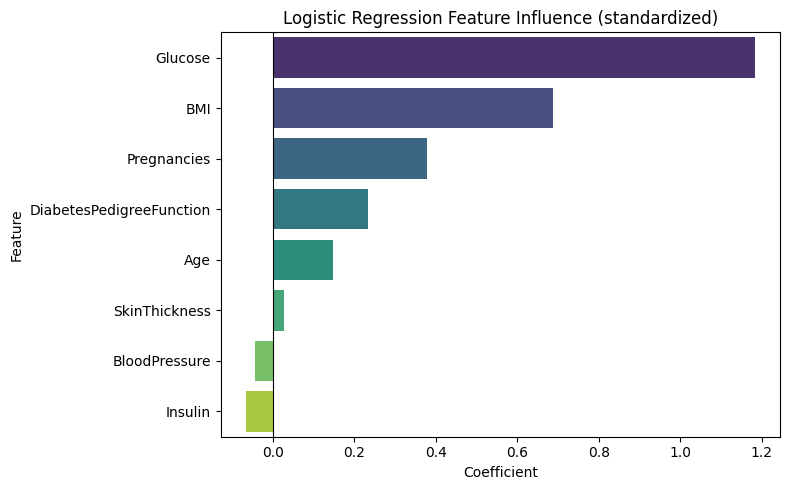

In [27]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0],
}).sort_values('Coefficient', ascending=False)

print(coefficients.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=coefficients, x='Coefficient', y='Feature', palette='viridis')
plt.title('Logistic Regression Feature Influence (standardized)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

### 4.2 Interpretation & Conclusions

- **Overall accuracy** on unseen data is roughly **0.75-0.79**, a solid result for this classic benchmark.
- **Train vs test** scores are close, so the model is **not overfitting** and generalises to new patients.
- **Glucose** is consistently the strongest predictor of diabetes, followed by **BMI**, **Age**, and **Pregnancies** - which matches real clinical knowledge.